In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters
BATCH_SIZE = 128
LEARNING_RATE = 0.0002
EPOCHS = 50
LATENT_DIM = 100

print("Device:", device)
print("Latent Dimension:", LATENT_DIM)

Device: cuda
Latent Dimension: 100


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

original_train = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

original_test = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    original_train,
    original_test
])

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator_seed = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator_seed
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Training batches:", len(train_loader))

Training: 56000
Validation: 7000
Testing: 7000
Training batches: 437


In [3]:
class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super(DCGANGenerator, self).__init__()

        self.model = nn.Sequential(
            # Input: 100 x 1 x 1
            nn.ConvTranspose2d(
                latent_dim, 128,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 128 x 7 x 7 -> 64 x 14 x 14
            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 64 x 14 x 14 -> 1 x 28 x 28
            nn.ConvTranspose2d(
                64, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Tanh()
        )

    def forward(self, z):
        z = z.view(z.size(0), -1, 1, 1)
        return self.model(z)

In [4]:
class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super(DCGANDiscriminator, self).__init__()

        self.model = nn.Sequential(
            # 1 x 28 x 28 -> 64 x 14 x 14
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # 64 x 14 x 14 -> 128 x 7 x 7
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),

            nn.Linear(128 * 7 * 7, 1)
        )

    def forward(self, x):
        return self.model(x)

In [5]:
generator = DCGANGenerator(
    latent_dim=LATENT_DIM
).to(device)

discriminator = DCGANDiscriminator().to(device)

print("GENERATOR")
print(generator)

print("\nDISCRIMINATOR")
print(discriminator)

GENERATOR
DCGANGenerator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)

DISCRIMINATOR
DCGANDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten

In [6]:
def weights_init(m):
    classname = m.__class__.__name__

    if "Conv" in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)

    elif "BatchNorm" in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


generator.apply(weights_init)
discriminator.apply(weights_init)

print("DCGAN weights initialized!")

DCGAN weights initialized!


In [7]:
criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999)
)

print("Loss function and optimizers initialized!")

Loss function and optimizers initialized!


In [8]:
# Test Generator
test_noise = torch.randn(4, LATENT_DIM, device=device)

fake_images = generator(test_noise)

print("Generated Images Shape:", fake_images.shape)

# Test Discriminator
output = discriminator(fake_images)

print("Discriminator Output Shape:", output.shape)

# Check image range
print("Minimum Pixel:", fake_images.min().item())
print("Maximum Pixel:", fake_images.max().item())

Generated Images Shape: torch.Size([4, 1, 28, 28])
Discriminator Output Shape: torch.Size([4, 1])
Minimum Pixel: -0.6638453006744385
Maximum Pixel: 0.5766412019729614


In [9]:
def train_dcgan(generator, discriminator, train_loader, epochs):

    G_losses = []
    D_losses = []

    for epoch in range(epochs):

        generator.train()
        discriminator.train()

        running_G_loss = 0.0
        running_D_loss = 0.0

        for real_images, _ in train_loader:

            real_images = real_images.to(device)
            batch_size = real_images.size(0)

            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            # Train Discriminator
            optimizer_D.zero_grad()

            real_output = discriminator(real_images)
            real_loss = criterion(real_output, real_labels)

            noise = torch.randn(batch_size, LATENT_DIM, device=device)
            fake_images = generator(noise)

            fake_output = discriminator(fake_images.detach())
            fake_loss = criterion(fake_output, fake_labels)

            d_loss = real_loss + fake_loss

            d_loss.backward()
            optimizer_D.step()

            # Train Generator
            optimizer_G.zero_grad()

            noise = torch.randn(batch_size, LATENT_DIM, device=device)
            generated_images = generator(noise)

            output = discriminator(generated_images)

            g_loss = criterion(output, real_labels)

            g_loss.backward()
            optimizer_G.step()

            running_G_loss += g_loss.item()
            running_D_loss += d_loss.item()

        avg_G_loss = running_G_loss / len(train_loader)
        avg_D_loss = running_D_loss / len(train_loader)

        G_losses.append(avg_G_loss)
        D_losses.append(avg_D_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Generator Loss: {avg_G_loss:.4f} "
            f"Discriminator Loss: {avg_D_loss:.4f}"
        )

    return G_losses, D_losses

In [10]:
G_losses, D_losses = train_dcgan(
    generator,
    discriminator,
    train_loader,
    EPOCHS
)

Epoch [1/50] Generator Loss: 1.8841 Discriminator Loss: 0.6234
Epoch [2/50] Generator Loss: 1.5039 Discriminator Loss: 0.8014
Epoch [3/50] Generator Loss: 1.2222 Discriminator Loss: 0.9765
Epoch [4/50] Generator Loss: 1.0885 Discriminator Loss: 1.0676
Epoch [5/50] Generator Loss: 1.0354 Discriminator Loss: 1.1172
Epoch [6/50] Generator Loss: 1.0053 Discriminator Loss: 1.1435
Epoch [7/50] Generator Loss: 0.9922 Discriminator Loss: 1.1585
Epoch [8/50] Generator Loss: 0.9888 Discriminator Loss: 1.1630
Epoch [9/50] Generator Loss: 0.9818 Discriminator Loss: 1.1673
Epoch [10/50] Generator Loss: 0.9845 Discriminator Loss: 1.1681
Epoch [11/50] Generator Loss: 0.9802 Discriminator Loss: 1.1719
Epoch [12/50] Generator Loss: 0.9819 Discriminator Loss: 1.1743
Epoch [13/50] Generator Loss: 0.9783 Discriminator Loss: 1.1704
Epoch [14/50] Generator Loss: 0.9800 Discriminator Loss: 1.1743
Epoch [15/50] Generator Loss: 0.9827 Discriminator Loss: 1.1770
Epoch [16/50] Generator Loss: 0.9848 Discriminato

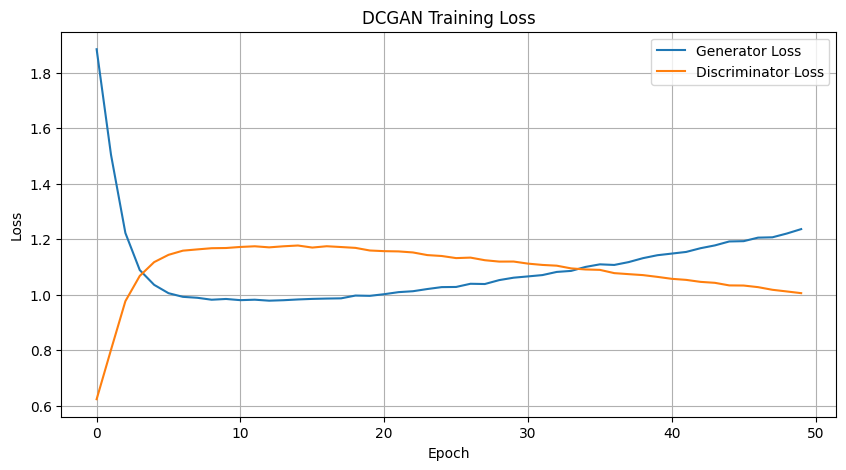

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")

plt.legend()
plt.grid(True)
plt.show()

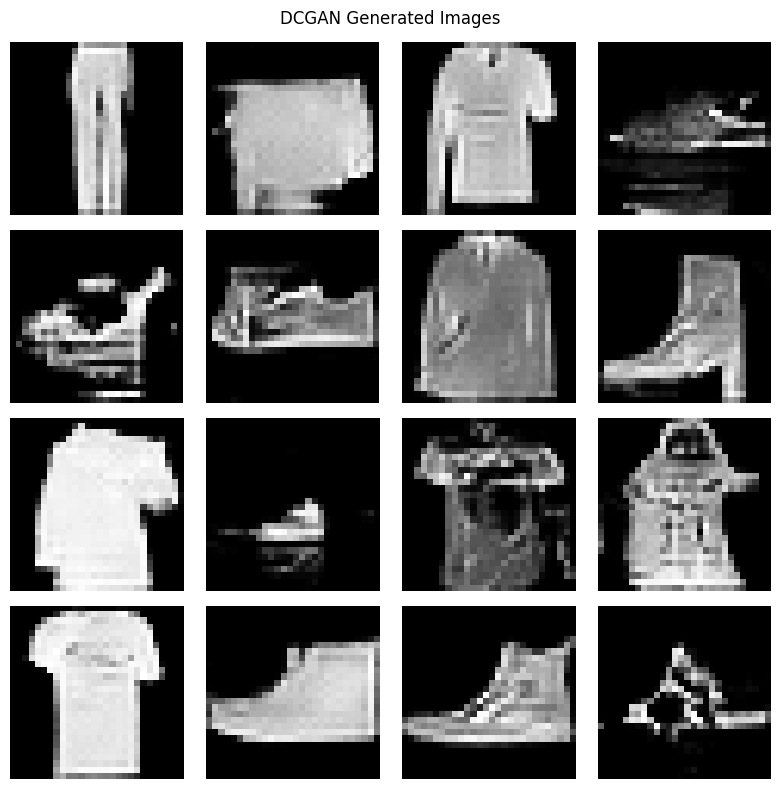

In [13]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(16, LATENT_DIM, device=device)
    generated_images = generator(noise)

# Convert [-1, 1] to [0, 1]
generated_images = (generated_images + 1) / 2

generated_images = generated_images.cpu()

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("DCGAN Generated Images")
plt.tight_layout()
plt.show()

In [14]:
import os
from torchvision.utils import save_image

os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/generated_images", exist_ok=True)

torch.save(
    generator.state_dict(),
    "../results/checkpoints/dcgan_generator.pth"
)

torch.save(
    discriminator.state_dict(),
    "../results/checkpoints/dcgan_discriminator.pth"
)

save_image(
    generated_images,
    "../results/generated_images/dcgan_generated.png",
    nrow=4
)

print("DCGAN results saved!")

DCGAN results saved!
